# 08 Model-based operator offset ratio (question 3)

The twin design (notebook 07) cannot run: no passive object flies near the Starlink shells. Here each
active satellite is its own control and the physics model gives the storm loss (`src/offset_model.py`).

For every active satellite (rows not flagged `free_drag`, outside orbit changes) and every storm:

- **predicted storm loss** = sum over the window of (MSIS 2.1 with actual ap - MSIS 2.1 with the storm's
  quiet ap) x dt, with the satellite's catalog-scaled B;
- **observed storm loss** = sum over the window of (observed decay - the satellite's own baseline over
  days -10..-3) x dt;
- windows: ducking (main_onset to recovery_end) and recovery (next 10 days);
- **offset = 1 - observed / predicted** (ratio of sums over all storm-satellite pairs), per window and
  total; 95% CIs from a storm-clustered wild bootstrap (Webb weights).

All 20 storms (no clean-window rule), with and without May / Oct 2024. Model-error correction from the
passive cohort's Y_residual by storm class and altitude band. Placebo: free-drag Starlinks.
Question 3 is a Starlink study: all 21 satellites used here are Starlinks.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import offset_model as om
from src import plots
from src.schema import load_table
from src.storms import load_storms

RESULTS = ROOT / "results"
table = load_table()
storms = load_storms()
out = om.run(table, storms, n_boot=999, seed=0)    # same as python -m src.causal_run
pairs = out["pairs"]
print(f"{len(pairs)} storm-satellite pairs, {pairs['norad_id'].nunique()} satellites, "
      f"{pairs['storm_id'].nunique()} storms")

282 storm-satellite pairs, 21 satellites, 20 storms


## 1. Which rows count

Rows flagged `free_drag` (notebook 07) are out. On top of that, `orbit_change_flags` drops rows inside a
21-day window whose net altitude change is more than 1 km either way: orbit raises and shell changes
(STARLINK-30105 is raised from 444 to 481 km in March 2025) are operator moves unrelated to storms, and
they swamped the recovery window (+-20-37 km) in a first run.

In [2]:
active = table[(table["is_active"] == 1) & (table["free_drag"] == 0)]
flags = om.orbit_change_flags(active)
print(f"orbit-change rows: {int(flags.sum())} of {len(active)}")
active[flags == 1].groupby("object_name").size()

orbit-change rows: 533 of 12835


object_name
STARLINK-1010      47
STARLINK-1013      43
STARLINK-1015     129
STARLINK-30105    203
STARLINK-30254     40
STARLINK-30275     71
dtype: int64

## 2. Passive model error used for the correction (m/day, Y_residual window minus pre)

In [3]:
e = out["errors"]
e[e["band"].isin(["400-500", "500-600"]) | e["band"].isna()].round(2)

,storm_class,band,window,delta,n_objects,n_storms
0,extreme,400-500,duck,-9.40,5,1
1,extreme,400-500,rec,-12.77,5,1
2,extreme,500-600,duck,-7.93,24,1
3,extreme,500-600,rec,-14.96,24,1
8,moderate,400-500,duck,-2.88,5,11
9,moderate,400-500,rec,2.94,5,11
10,moderate,500-600,duck,-4.39,24,11
11,moderate,500-600,rec,4.21,24,11
16,severe,400-500,duck,8.48,5,2
17,severe,400-500,rec,-0.66,5,2


MSIS 2.1 under-predicts storm decay for moderate / strong / extreme storms at 400-600 km (delta -3 to
-15 m/day) and over-predicts for the two severe storms (+6 to +8). The correction moves the predicted
loss accordingly; the 400-500 km band rests on only 5 passive objects.

## 3. Offset ratios

In [4]:
out["summary"].round(3)

est  ci_lo  ci_hi     se  n_storms  \
storms         prediction  statistic                                            
all storms     uncorrected offset_duck   1.211  1.093  1.335  0.062        20   
                           offset_rec    1.029 -0.853  2.819  0.946        20   
                           offset_total  1.190  0.974  1.415  0.117        20   
                           duck_part     1.072  0.967  1.181  0.055        20   
                           rec_part      0.119 -0.098  0.325  0.109        20   
               corrected   offset_duck   1.198  1.084  1.313  0.059        20   
                           offset_rec    1.024 -0.489  2.465  0.761        20   
                           offset_total  1.175  0.977  1.379  0.106        20   
                           duck_part     1.041  0.942  1.141  0.051        20   
                           rec_part      0.134 -0.064  0.323  0.100        20   
without 3,4,11 uncorrected offset_duck   1.244  1.054  1.430  0.099        17   
                           offset_rec    0.398 -2.617  3.395  1.571        17   
                           offset_total  1.394  0.892  1.918  0.268        17   
                           duck_part     1.465  1.242  1.685  0.117        17   
                           rec_part     -0.071 -0.605  0.466  0.280        17   
               corrected   offset_duck   1.226  1.053  1.401  0.091        17   
                           offset_rec    0.442 -2.254  3.121  1.415        17   
                           offset_total  1.365  0.904  1.837  0.240        17   
                           duck_part     1.443  1.239  1.650  0.108        17   
                           rec_part     -0.078 -0.554  0.400  0.251        17   

                                         n_objects  n_pairs  
storms         prediction  statistic                         
all storms     uncorrected offset_duck          21      282  
                           offset_rec           21      282  
                           offset_total         21      282  
                           duck_part            21      282  
                           rec_part             21      282  
               corrected   offset_duck          21      282  
                           offset_rec           21      282  
                           offset_total         21      282  
                           duck_part            21      282  
                           rec_part             21      282  
without 3,4,11 uncorrected offset_duck          21      234  
                           offset_rec           21      234  
                           offset_total         21      234  
                           duck_part            21      234  
                           rec_part             21      234  
               corrected   offset_duck          21      234  
                           offset_rec           21      234  
                           offset_total         21      234  
                           duck_part            21      234  
                           rec_part             21      234

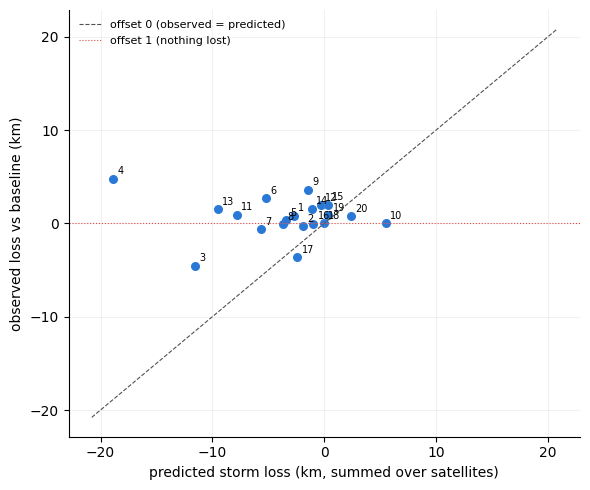

In [5]:
plots.plot_offset_model_storms(pairs, storms, out_path=RESULTS / "offset_model_storms.png");

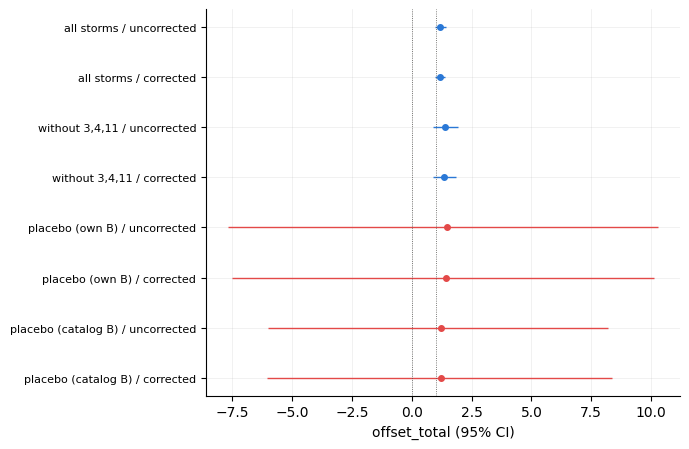

In [6]:
plots.plot_offset_model_summary(out["summary"], out["placebo"], out_path=RESULTS / "offset_model_summary.png");

- **Total offset 1.19 (95% CI 0.97 to 1.42)**, corrected 1.18 (0.98 to 1.38); without May / Oct 2024
  1.39 (0.89 to 1.92). The Starlinks lose no more altitude around storms than in their pre-storm baseline:
  operators undo the whole predicted storm loss.
- It happens during the storm: ducking window 1.21 (1.09 to 1.34), ducking part of the total 1.07; the
  recovery part is 0.12 (-0.10 to 0.33), so there is little left to climb back.
- Values above 1 mean the satellites decayed a little *less* than their baseline. The station-keeping
  thrust (or a drag-reducing attitude) more than covers the storm, or the baseline (days -10..-3) is
  itself dented by neighbouring storms: with all 20 storms used, windows overlap.
- Per storm (figure): observed loss stays near zero whatever the prediction. May 2024 (storm 4) was
  predicted to cost ~19 km summed over the satellites; they ended ~5 km above baseline. Storm 3 (May 2) is
  the one clear loss: its 10-day recovery window runs into the May 10 superstorm (windows overlap).
- The recovery-window ratio (1 - O_rec / P_rec) is noisy because the predicted loss after recovery_end is
  small; the additive parts are the readable split.

## 4. Drag-sensitivity scale

In [7]:
out["b_sensitivity"].round(3)

b_scale,0.75,1.25
offset_duck,1.282,1.169
offset_rec,1.039,1.023
offset_total,1.254,1.152
duck_part,1.134,1.034
rec_part,0.120,0.118


The predicted loss scales with B (catalog x 0.71-0.77). If the true B were 0.75x or 1.25x that, the total
offset would be 1.25 or 1.15: the conclusion (operators undo about all of it) does not hinge on the
catalog scale.

## 5. Placebo: free-drag Starlinks

In [8]:
print(out["placebo_b_scale"].round(2).rename("own fitted / catalog B").to_string())
out["placebo"].round(3)

norad_id
47654    0.96
50188    0.51
52555    0.54
53611    0.53
53910    0.41
54092    0.25
55473    0.52
55917    0.81
57433    0.36
57533    0.21
57667    1.22


est    ci_lo    ci_hi      se  \
b         prediction  statistic                                        
own B     uncorrected offset_duck    0.334   -0.671    1.288   0.512   
                      offset_rec   -11.854 -102.447   80.056  48.093   
                      offset_total   1.469   -7.700   10.308   4.663   
                      duck_part      0.365   -0.733    1.407   0.559   
                      rec_part       1.104   -7.453    9.537   4.477   
          corrected   offset_duck    0.381   -0.555    1.272   0.474   
                      offset_rec   -12.821 -116.837   95.711  54.811   
                      offset_total   1.431   -7.514   10.103   4.510   
                      duck_part      0.411   -0.599    1.374   0.511   
                      rec_part       1.020   -7.614    9.294   4.360   
catalog B uncorrected offset_duck    0.654    0.130    1.149   0.266   
                      offset_rec   -11.372 -156.049  133.439  78.007   
                      offset_total   1.234   -5.999    8.187   3.798   
                      duck_part      0.685    0.136    1.205   0.279   
                      rec_part       0.549   -6.439    7.530   3.764   
          corrected   offset_duck    0.667    0.166    1.145   0.255   
                      offset_rec   -12.265 -178.705  153.028  88.006   
                      offset_total   1.224   -6.075    8.387   3.819   
                      duck_part      0.695    0.173    1.195   0.266   
                      rec_part       0.529   -6.597    7.703   3.794   

                                    n_storms  n_objects  n_pairs  
b         prediction  statistic                                   
own B     uncorrected offset_duck         20         11      141  
                      offset_rec          20         11      141  
                      offset_total        20         11      141  
                      duck_part           20         11      141  
                      rec_part            20         11      141  
          corrected   offset_duck         20         11      141  
                      offset_rec          20         11      141  
                      offset_total        20         11      141  
                      duck_part           20         11      141  
                      rec_part            20         11      141  
catalog B uncorrected offset_duck         20         11      141  
                      offset_rec          20         11      141  
                      offset_total        20         11      141  
                      duck_part           20         11      141  
                      rec_part            20         11      141  
          corrected   offset_duck         20         11      141  
                      offset_rec          20         11      141  
                      offset_total        20         11      141  
                      duck_part           20         11      141  
                      rec_part            20         11      141

Placebo objects: Starlink rows flagged `free_drag` of satellites whose own quiet decay is at most 1.5x the
catalog free-drag rate (11 satellites; STARLINK-1010 / 1013 / 1015 / 30264 / 30277 decay 3-22x faster:
they are thrust down, not decaying by drag). Their B is refitted on their own quiet rows (0.2-1.2 x
catalog), as for passive objects.

- With own B, the ducking-window offset is 0.33 (95% CI -0.67 to 1.29), corrected 0.38: compatible with 0,
  but imprecise, and the point estimate is not small.
- The placebo total (1.47, CI -7.7 to 10.3) is uninformative: a deorbiting satellite decays faster every
  week, so its pre-storm baseline understates the later decay, and the recovery window is mostly that drift.
- With the catalog B (no refit) the ducking offset is 0.65 (0.13 to 1.15): a B that is ~2x too big fakes an
  offset of about one half. For the station-keeping satellites B cannot be refitted, which is why the B-scale
  sensitivity above matters.

So the placebo does not reject the method, but it is a weak check: it rests on 11 satellites whose orbits
are changing, and its ducking point estimate (0.33) leaves room for a positive bias of that size.

## 6. Conclusion

- Active Starlinks offset about all of the storm's predicted orbit loss (total 1.19, CI 0.97-1.42;
  corrected 1.18, 0.98-1.38), almost entirely during the storm itself (ducking part 1.07) rather than by
  climbing back afterwards (recovery part 0.12).
- Holds without May / Oct 2024 (1.39, 0.89-1.92), for a 25% wrong B scale (1.15-1.25), and after the
  passive model-error correction.
- Caveats: one operator (Starlink) with continuous low-thrust station keeping, so this is "Starlink offsets
  storms" more than "operators do"; catalog-based B; overlapping storm windows; a weak placebo.